<span style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">An Exception was encountered at '<a href="#papermill-error-cell">In [5]</a>'.</span>

# Technical evaluation: runtime profiling

In [2]:
QUICK = True            # Set to False for full runs
RUN_EXPERIMENTS = True  # Set to False to skip running experiments, and only re-run visualization code.

In [3]:
import json
import sys
import os
from collections import defaultdict
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
from workflow_utils.plot_style import ANNOTATION_GREY, AREA_ALPHA, MARKERS, PALETTE
from workflow_utils.utils import OUTPATH_TECH_EVAL as OUTPATH
from IPython.display import Markdown, display
import numpy as np

FIGPATH = f"{OUTPATH}/runtimes"
RESULTSPATH = f"{OUTPATH}/runtimes"

SEED = 1

## Data collection

To collect all data for this evaluation, we run two `bash`-scripts. All data is stored to allow for easy analysis afterwards.

In [4]:
SCRIPT_DIR = Path("tech_eval_utils")
if RUN_EXPERIMENTS:
    args = ["--quick"] if QUICK else []
    # run with the notebook's interpreter; the scripts run one after the other, as concurrent runs distort the timings
    env = {**os.environ, "PYTHON": sys.executable, "RESULTS_DIR": os.path.abspath(RESULTSPATH)}
    for script in ["collect_runtimes.sh", "collect_scaling.sh"]:
        subprocess.run(["bash", str(SCRIPT_DIR / script), *args], env=env, check=True)

MountainCarContinuous-v0 | ActiveLearning | budget 10000 (10 x 1000) | 100 states, 10 action bins | seed 0
  Written to ../output/tech_eval/runtimes/quick/MountainCarContinuous-v0__ActiveLearning__10000__s10a10__seed0.json
Done, 0 failed run(s).
MountainCarContinuous-v0 | Entropy | budget 1000 (1 x 1000) | 625 states, 10 action bins | seed 0
  Written to ../output/tech_eval/runtimes/quick/MountainCarContinuous-v0__Entropy__1000__s25a10__seed0.json
MountainCarContinuous-v0 | Entropy | budget 10000 (10 x 1000) | 625 states, 10 action bins | seed 0
  Written to ../output/tech_eval/runtimes/quick/MountainCarContinuous-v0__Entropy__10000__s25a10__seed0.json
Done, 0 failed run(s).


## Visualization

Visualizes the runs written by `run_profiling.py` to `data/` (one JSON file per (env, policy, budget, bins, seed) run),
collected with `collect_runtimes.sh` and `collect_scaling.sh`.

In [5]:
DATA_DIR = Path(RESULTSPATH) / "quick" if QUICK else Path(RESULTSPATH)
POLICY_ORDER = ["Random", "Q-Learning", "ActiveLearning", "Entropy"]
# fixed color/marker per policy, so a policy looks the same in every plot
POLICY_STYLE = {p: dict(color=c, marker=m) for p, c, m in zip(POLICY_ORDER, PALETTE, MARKERS)}

# timing categories reported by verigym.create_abstraction, with display labels
TIME_CATEGORIES = {
    "time_simulate": "Simulation",
    "time_model_construction": "Model construction",
    "time_policy_update": "Policy update",
}
STORMPY_LABEL = "Stormpy (build + check)"
SCALING_BINS = (25, 10)  # (state bins, action bins) used by collect_scaling.sh

# load all runs

all_records = [json.loads(f.read_text()) for f in sorted(DATA_DIR.glob("*.json"))]
for r in all_records:
    # older runs did not record the model checking time
    r["t_stormpy"] = r["t_stormpy_build"] + r.get("t_model_check", 0.0)
    # everything needed to obtain the policy; the evaluation itself is excluded
    r["time_total"] = sum(r[k] for k in TIME_CATEGORIES) + r["t_stormpy"]
print(f"Loaded {len(all_records)} runs from {DATA_DIR}")


Loaded 3 runs from /home/merlijn/GitRepos/VeriGym/docs/workflows/output/tech_eval/runtimes/quick


## Runtime breakdown

A fixed environment and policy. Left: results of `collect_runtimes.sh`, a fixed budget with an increasing number of
state bins, against the number of state-action pairs in the abstraction (abstract states × action bins). Right: results
of `collect_scaling.sh` with the binning of the scaling section below, against the exploration budget.
Each line shows one runtime component; the black line is their sum. Lines show the mean over seeds, bands the min/max.

<span id="papermill-error-cell" style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">Execution using papermill encountered an exception here and stopped:</span>

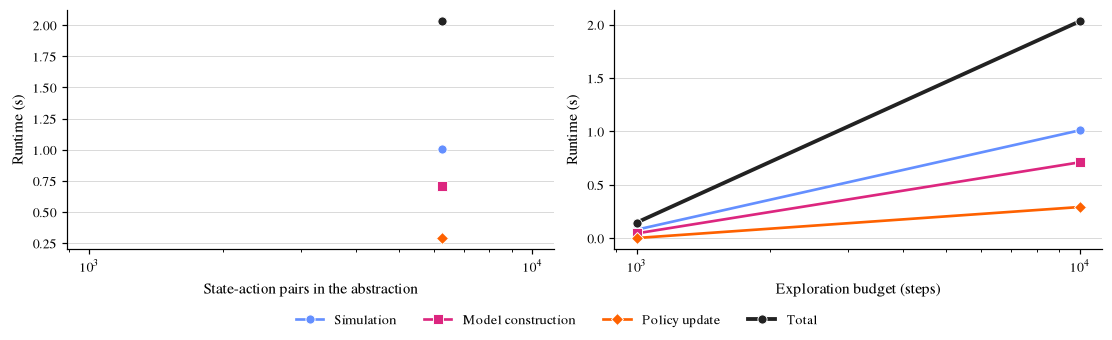

In [6]:
BREAKDOWN_ENV = "MountainCarContinuous-v0"
POLICY = "Entropy"
BUDGET = 100_000 if not QUICK else 10_000  # matches collect_runtimes.sh
BINS_ACTIONS = 10
MAX_BUDGET = np.inf #500_000  # largest budget in the breakdown against the budget
TOTAL_COLOR = "#222222"

# seeds per number of state bins for this env, policy, budget and action bins
breakdown = defaultdict(list)
for r in all_records:
    if (r["env"], r["policy"], r["budget"], r["bins_actions"]) == (BREAKDOWN_ENV, POLICY, BUDGET, BINS_ACTIONS):
        breakdown[r["bins_states"]].append(r)
bins = sorted(breakdown)
if not bins:
    raise ValueError(f"No runs for {BREAKDOWN_ENV}, {POLICY}, budget {BUDGET}, {BINS_ACTIONS} action bins in {DATA_DIR}, "
                     "run collect_runtimes.sh")

# seeds per budget (up to MAX_BUDGET) for this env, policy and binning
budget_breakdown = defaultdict(list)
for r in all_records:
    if (r["env"], r["policy"], r["bins_states"], r["bins_actions"]) == (BREAKDOWN_ENV, POLICY, *SCALING_BINS) \
            and r["budget"] <= MAX_BUDGET:
        budget_breakdown[r["budget"]].append(r)
budgets = np.array(sorted(budget_breakdown))
if not len(budgets):
    raise ValueError(f"No runs for {BREAKDOWN_ENV}, {POLICY}, bins {SCALING_BINS}, budget <= {MAX_BUDGET:,} in {DATA_DIR}, run collect_scaling.sh")

# number of state-action pairs in the abstraction
n_sa = np.array([breakdown[b][0]["n_abstract_states"] * BINS_ACTIONS for b in bins])

def stats(groups, key):
    """Mean/min/max over seeds of `key`, for each group of runs in `groups`."""
    values = [np.array([r[key] for r in group]) for group in groups]
    return (np.array([v.mean() for v in values]), np.array([v.min() for v in values]),
            np.array([v.max() for v in values]))

lines = {**TIME_CATEGORIES, "time_total": "Total"}
colors = [*PALETTE[:len(lines) - 1], TOTAL_COLOR]

fig, (ax_size, ax_budget) = plt.subplots(1, 2, figsize=(10, 3))
for (key, label), color, marker in zip(lines.items(), colors, [*MARKERS[:len(lines) - 1], "o"]):
    for ax, x, groups in ((ax_size, n_sa, [breakdown[b] for b in bins]),
                          (ax_budget, budgets, [budget_breakdown[b] for b in budgets])):
        mean, lo, hi = stats(groups, key)
        ax.plot(x, mean, color=color, marker=marker, label=label,
                linewidth=2.5 if key == "time_total" else None)
        ax.fill_between(x, lo, hi, color=color, alpha=AREA_ALPHA, linewidth=0)

for ax in (ax_size, ax_budget):
    ax.set_xscale("log")
    ax.set_ylabel("Runtime (s)")
ax_size.set_xlabel("State-action pairs in the abstraction")
# ax_size.set_title(f"Runtime against abstraction size ({BUDGET:,} steps)")
ax_budget.set_xlabel("Exploration budget (steps)")
# ax_budget.set_title(f"Runtime against exploration budget ({SCALING_BINS[0]} state bins)")

fig.legend(*ax_size.get_legend_handles_labels(), loc="outside lower center", ncol=len(lines), frameon=False)
plt.savefig("runtime_breakdown.pdf")
plt.show()

### Share of the total runtime

The same runs as above, with each component as a percentage of the total runtime of its run. Stormpy (building and
checking the model) is included so the components sum to 100%. Lines show the mean over seeds, bands the min/max.

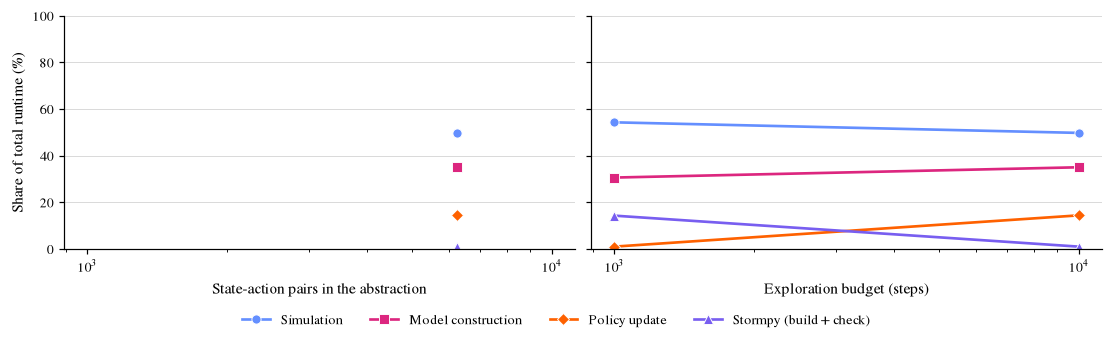

In [7]:
shares = {**TIME_CATEGORIES, "t_stormpy": STORMPY_LABEL}

def share_stats(groups, key):
    """Mean/min/max over seeds of `key` as a percentage of the total runtime, for each group of runs in `groups`."""
    values = [np.array([100 * r[key] / r["time_total"] for r in group]) for group in groups]
    return (np.array([v.mean() for v in values]), np.array([v.min() for v in values]),
            np.array([v.max() for v in values]))

fig, (ax_size, ax_budget) = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for (key, label), color, marker in zip(shares.items(), PALETTE, MARKERS):
    for ax, x, groups in ((ax_size, n_sa, [breakdown[b] for b in bins]),
                          (ax_budget, budgets, [budget_breakdown[b] for b in budgets])):
        mean, lo, hi = share_stats(groups, key)
        ax.plot(x, mean, color=color, marker=marker, label=label)
        ax.fill_between(x, lo, hi, color=color, alpha=AREA_ALPHA, linewidth=0)

for ax in (ax_size, ax_budget):
    ax.set_xscale("log")
ax_size.set_ylabel("Share of total runtime (%)")
ax_size.set_ylim(0, 100)
ax_size.set_xlabel("State-action pairs in the abstraction")
ax_budget.set_xlabel("Exploration budget (steps)")

fig.legend(*ax_size.get_legend_handles_labels(), loc="outside lower center", ncol=len(shares), frameon=False)
plt.savefig(f"{FIGPATH}/runtime_breakdown_share.pdf")
plt.show()

## Scaling with the exploration budget

Results of `collect_scaling.sh`: one JSON file per (env, policy, budget, seed) run in `data/`, with 10 state bins and 10 action bins.

In [8]:
ENV = "MountainCarContinuous-v0"

records = [r for r in all_records if r["env"] == ENV and (r["bins_states"], r["bins_actions"]) == SCALING_BINS]

# group the seeds of each (policy, budget): runs[policy][budget] -> list of records
runs = defaultdict(lambda: defaultdict(list))
for r in records:
    runs[r["policy"]][r["budget"]].append(r)
policies = [p for p in POLICY_ORDER if p in runs]

def series(policy, key):
    """Budgets and mean/min/max over seeds of `key`, sorted by budget."""
    budgets = sorted(runs[policy])
    values = [np.array([r[key] for r in runs[policy][b]]) for b in budgets]
    return (np.array(budgets), np.array([v.mean() for v in values]),
            np.array([v.min() for v in values]), np.array([v.max() for v in values]))

print(f"Loaded {len(records)} runs for {ENV}: " + ", ".join(f"{p} ({sum(map(len, runs[p].values()))})" for p in policies))


Loaded 2 runs for MountainCarContinuous-v0: Entropy (2)


### Summary table

Means over seeds; ± is the standard deviation over seeds (only shown with more than one seed).

In [9]:
def fmt(values, digits=1):
    values = np.asarray(values, dtype=float)
    s = f"{values.mean():.{digits}f}"
    return s + f" ± {values.std():.{digits}f}" if len(values) > 1 else s

header = ["Policy", "Budget", "Seeds", "Total time (s)", "Simulation (s)", "Policy update (s)",
          "Model constr. (s)", "Explored S", "Explored SA", "Return original"]
rows = []
for p in policies:
    for b in sorted(runs[p]):
        rs = runs[p][b]
        col = lambda k: [r[k] for r in rs]
        rows.append([p, f"{b:,}", str(len(rs)), fmt(col("time_total"), 2), fmt(col("time_simulate"), 2),
                     fmt(col("time_policy_update"), 2), fmt(col("time_model_construction"), 2),
                     fmt(col("explored_states"), 0), fmt(col("explored_state_action_pairs"), 0),
                     fmt(col("mean_reward_original"))])

lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
lines += ["| " + " | ".join(row) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| Policy | Budget | Seeds | Total time (s) | Simulation (s) | Policy update (s) | Model constr. (s) | Explored S | Explored SA | Return original |
|---|---|---|---|---|---|---|---|---|---|
| Entropy | 1,000 | 1 | 0.15 | 0.08 | 0.00 | 0.04 | 170 | 741 | -15.4 |
| Entropy | 10,000 | 1 | 2.03 | 1.01 | 0.29 | 0.71 | 347 | 3029 | 0.0 |

### Coverage and policy value vs. budget

Solid lines (left axis) show the explored state-action pairs; dotted lines (right axis) the mean episode return of the
abstraction's optimal policy on the original environment. Lines show the mean over seeds, bands the min/max over seeds.

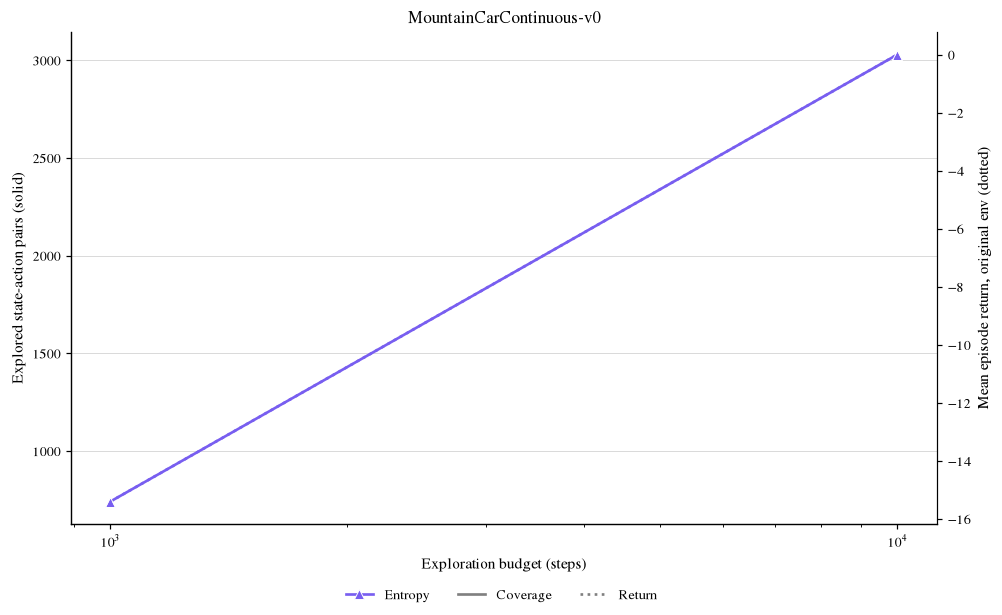

In [10]:
from matplotlib.lines import Line2D

def plot_series(ax, x, mean, lo, hi, style, **kwargs):
    ax.plot(x, mean, color=style["color"], marker=style["marker"], **kwargs)
    # if np.any(lo != hi):
    #     ax.fill_between(x, lo, hi, color=style["color"], alpha=AREA_ALPHA, linewidth=0)

fig, ax_cov = plt.subplots(figsize=(9, 5.5))
ax_val = ax_cov.twinx()

for p in policies:
    style = POLICY_STYLE[p]
    plot_series(ax_cov, *series(p, "explored_state_action_pairs"), style, label=p)
    plot_series(ax_val, *series(p, "mean_reward_original"), style, linestyle=":", markerfacecolor="none")

ax_cov.set_xscale("log")
ax_cov.set_xlabel("Exploration budget (steps)")
ax_cov.set_ylabel("Explored state-action pairs (solid)")
ax_val.set_ylabel("Mean episode return, original env (dotted)")
ax_val.spines["right"].set_visible(True)
ax_val.grid(False)
ax_cov.set_title(ENV)

# legend: color identifies the policy, line style the metric
policy_handles, policy_labels = ax_cov.get_legend_handles_labels()
metric_handles = [Line2D([], [], color=ANNOTATION_GREY, linestyle="-"),
                  Line2D([], [], color=ANNOTATION_GREY, linestyle=":")]
fig.legend(policy_handles + metric_handles, policy_labels + ["Coverage", "Return"],
           loc="outside lower center", ncol=len(policies) + 2, frameon=False)
plt.show()


### Coverage, policy value and runtime vs. budget (separate panels)

Lines show the mean over seeds. Runtime is the time to obtain the policy, divided by the budget (exploration, model construction, stormpy
build and model checking); the evaluation of the final policy is excluded.

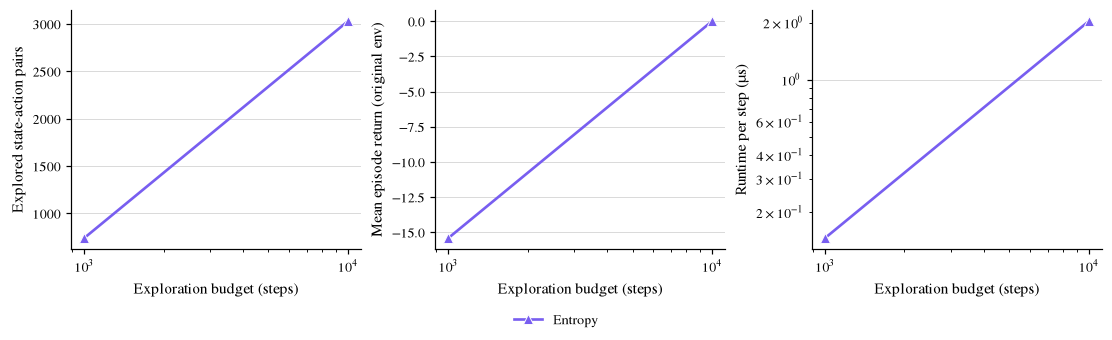

In [11]:
fig, (ax_cov, ax_val, ax_time) = plt.subplots(1, 3, figsize=(10, 3), sharex=True)

for p in policies:
    style = POLICY_STYLE[p]
    plot_series(ax_cov, *series(p, "explored_state_action_pairs"), style, label=p)
    plot_series(ax_val, *series(p, "mean_reward_original"), style)
    budgets, mean, lo, hi = series(p, "time_total")
    # per step, so the shared linear trend drops out and differences between policies remain
    # plot_series(ax_time, budgets, mean / budgets * 1e6, lo / budgets * 1e6, hi / budgets * 1e6, style)
    plot_series(ax_time, budgets, mean, lo , hi , style)

for ax in (ax_cov, ax_val, ax_time):
    ax.set_xscale("log")
    ax.set_xlabel("Exploration budget (steps)")

ax_cov.set_ylabel("Explored state-action pairs")
ax_val.set_ylabel("Mean episode return (original env)")
ax_time.set_ylabel("Runtime per step (µs)")
ax_time.set_yscale("log")

fig.legend(*ax_cov.get_legend_handles_labels(), loc="outside lower center", ncol=len(policies), frameon=False)
plt.savefig(f"{FIGPATH}/policy_vs_explore_budget.pdf")
plt.show()